In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

In [5]:
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["species"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
print("Shape:", df.shape)

print("\nInformation:")
print(df.info())

print("\nStatistics:")
print(df.describe())

Shape: (150, 5)

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB
None

Statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%    

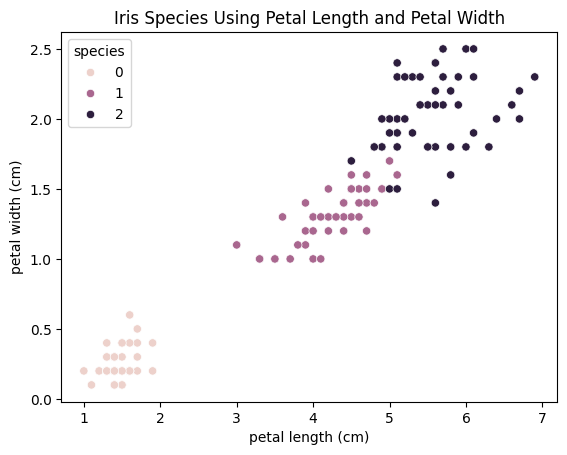

In [7]:
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species"
)

plt.title("Iris Species Using Petal Length and Petal Width")
plt.show()

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [9]:
pca = PCA(n_components=2)

pca_res = pca.fit_transform(X_scaled)

print("PCA shape:", pca_res.shape)

PCA shape: (150, 2)


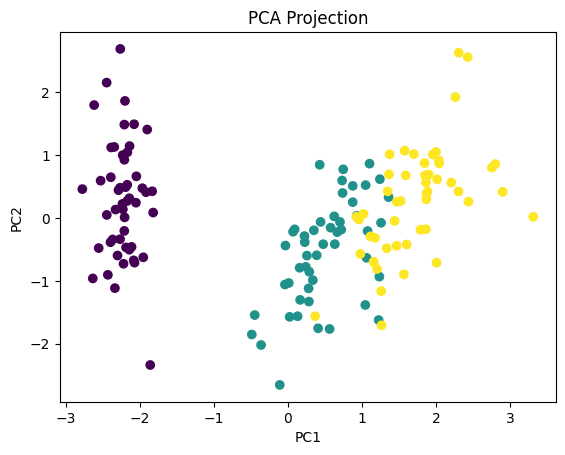

In [10]:
plt.scatter(
    pca_res[:, 0],
    pca_res[:, 1],
    c=y
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection")
plt.show()

In [11]:
tsne = TSNE(
    n_components=2,
    random_state=42
)

tsne_res = tsne.fit_transform(X_scaled)

print("t-SNE shape:", tsne_res.shape)

t-SNE shape: (150, 2)


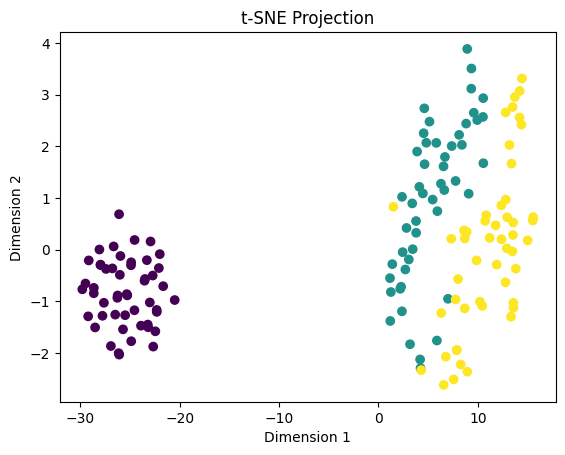

In [12]:
plt.scatter(
    tsne_res[:, 0],
    tsne_res[:, 1],
    c=y
)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("t-SNE Projection")
plt.show()

In [13]:
umap_model = umap.UMAP(
    n_components=2,
    random_state=42
)

umap_res = umap_model.fit_transform(X_scaled)

print("UMAP shape:", umap_res.shape)

UMAP shape: (150, 2)


C:\Users\Lab\AppData\Roaming\Python\Python39\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


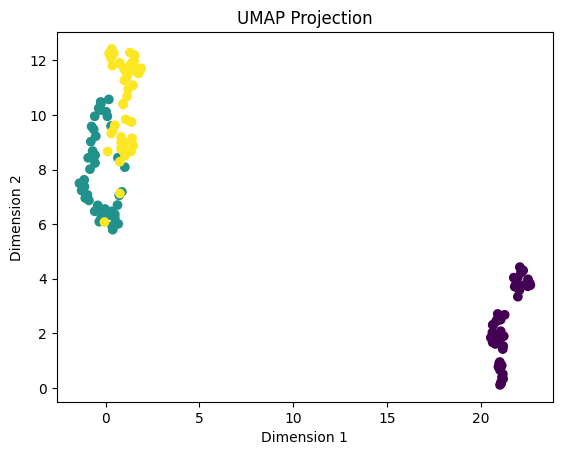

In [14]:
plt.scatter(
    umap_res[:, 0],
    umap_res[:, 1],
    c=y
)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("UMAP Projection")
plt.show()

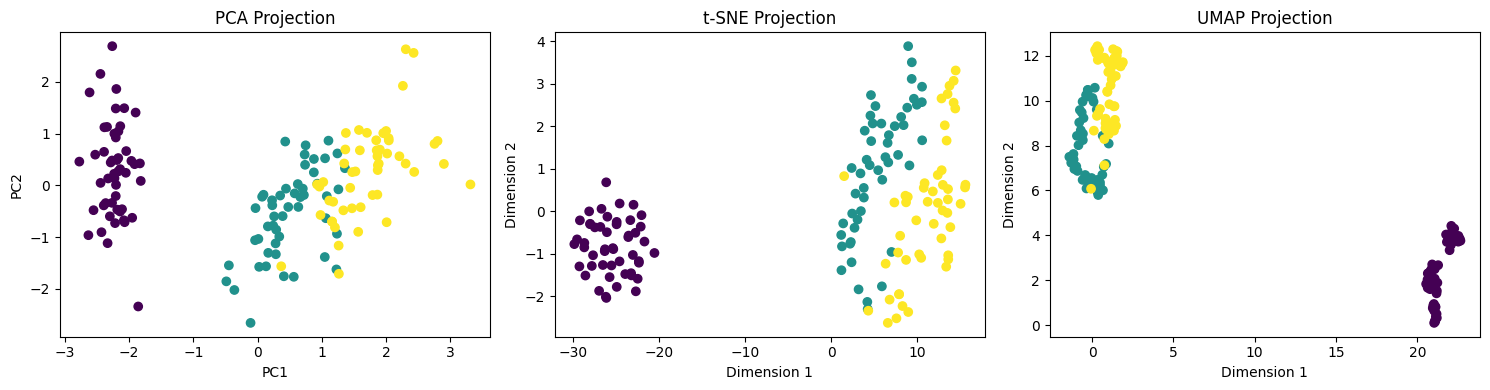

In [15]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

axes[0].scatter(
    pca_res[:, 0],
    pca_res[:, 1],
    c=y
)

axes[0].set_title("PCA Projection")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")


axes[1].scatter(
    tsne_res[:, 0],
    tsne_res[:, 1],
    c=y
)

axes[1].set_title("t-SNE Projection")
axes[1].set_xlabel("Dimension 1")
axes[1].set_ylabel("Dimension 2")


axes[2].scatter(
    umap_res[:, 0],
    umap_res[:, 1],
    c=y
)

axes[2].set_title("UMAP Projection")
axes[2].set_xlabel("Dimension 1")
axes[2].set_ylabel("Dimension 2")


plt.tight_layout()
plt.show()

C:\Users\Lab\AppData\Roaming\Python\Python39\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


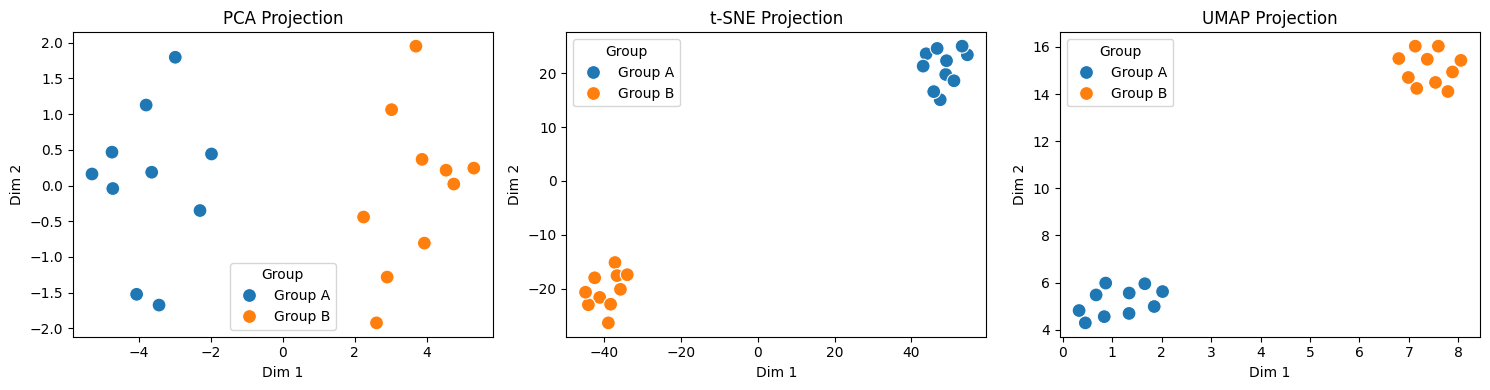

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap


# --- DATASET GENERATION (Do not change) ---
np.random.seed(42)

data = np.random.randn(20, 4)
data[10:, :] += 3.5

labels = ['Group A'] * 10 + ['Group B'] * 10

df = pd.DataFrame(
    data,
    columns=['F1', 'F2', 'F3', 'F4']
)

X_scaled = df.values


# --- PCA ---
pca_res = PCA(
    n_components=2
).fit_transform(X_scaled)


# --- t-SNE ---
tsne_res = TSNE(
    n_components=2,
    perplexity=5,
    random_state=42
).fit_transform(X_scaled)


# --- UMAP ---
umap_res = umap.UMAP(
    n_components=2,
    n_neighbors=5,
    random_state=42
).fit_transform(X_scaled)


# --- Plot all three ---
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

results = [
    ('PCA', pca_res),
    ('t-SNE', tsne_res),
    ('UMAP', umap_res)
]


for ax, (title, res_data) in zip(axes, results):

    plot_df = pd.DataFrame(
        res_data,
        columns=['Dim 1', 'Dim 2']
    )

    plot_df["Group"] = labels

    sns.scatterplot(
        data=plot_df,
        x='Dim 1',
        y='Dim 2',
        hue='Group',
        ax=ax,
        s=100
    )

    ax.set_title(f"{title} Projection")


plt.tight_layout()
plt.show()

"""Three Errors in the Provided Code
t-SNE Perplexity Error
perplexity=30 is too high for only 20 data points.
Fix: use perplexity=5.
Group Labels Missing
labels were created but not added to plot_df.
Fix: add plot_df["Group"] = labels and use hue='Group'.
Invalid LINE
The word LINE at the end of the sns.scatterplot() line is invalid Python.
Fix: remove LINE."""